# Lab 5 - Emission Lab Instruction

THEMIS - 100m resolution in thermal infrared, 10-bands:

```text
Band 1 & 2 (6.78 microns)
Band 3 (7.93 microns)
Band 4 (8.56 microns)
Band 5 (9.35 microns)
Band 6 (10.21 microns)
Band 7 (11.04 microns)
Band 8 (11.79 microns)
Band 9 (12.57 microns)
Band 10 (14.88 microns)
```

TES - 3 x 8 km resolution, Mars global surveys


In [8]:
import os
import matlab.engine

# Setup Working Directory for the notebook
DOCS_DIR = os.getcwd()
CWD = os.path.dirname(DOCS_DIR)
MATLAB_DIR = CWD + '/emission_lab_files'


# Start MATLAB ENGINE
engine = matlab.engine.start_matlab()
print(engine.version())
engine.addpath(MATLAB_DIR, nargout=0)

# Load THEMIS data file
engine.eval(
    "load('lab_emissivity_THEMIS.mat')", nargout=0
)

26.2.0.3386108 (R2026b)


## Multispectral Image Analysis - THEMIS

### Q1: What are we seeing in this daytime infrared image?


In [10]:
# Plot Daytime radiance of the AOI
engine.eval(
    "bandview(radiance, wvl_radiance)", nargout=0
)

These images show daytime thermal infrared radiance from the surface at different wavelengths. The mean radiance is relatively low in bands 1 and 2, which both sample 6.78 microns, and increases through bands 3–8, reaching its maximum in band 8 (11.79 microns). Mean radiance decreases slightly when moved from band 8 to 9 (12.57 microns), then drops sharply in band 10 (14.88 microns). Band 10 therefore appears very dark on the shared display scale.

Across the scene, opposing sides of crater rims and ridges shows differences in radiance, this is consistent with the fact that sunward facing slopes experience greater heating, therefore appears brighter on the images compare to surface sloping away.

|               Band 1               |               Band 8               |               Band 9                |
| :--------------------------------: | :--------------------------------: | :---------------------------------: |
| ![q1_band1.png](figs/q1_band1.png) | ![q1_band8.png](figs/q1_band8.png) | ![q1_band9.png](figs/q1_band10.png) |


### Q2: How many surface units would you define based on what you see in the radiance image? Briefly describe them.

The surface could be divided into different surface unit by their generic shape, craters, smooth surface, and rough surface along with strikes/trenches found in those open surface.

Between 1000 and 600, there is rough cribble surfaces. Moving up in the images, the upper portion of the image is mostly smooth surface, with few, looks like impact craters above 1400 mark.

the lower part of the image is relatively rougher compare to the upper portion of the image.


### Q3: In what band do you see the highest radiance, and what temperature does this equate to?


In [4]:
engine.eval(
    "calc_temp(" \
        "radiance(150,200,3:9)," \
        "wvl_radiance(3:9)" \
    ")", 
    nargout=0
)


ans =

  273.5122



![q3.png](figs/q3.png)

The highest radiance is in 12 microns, which is `band 8`, for the selected pixel at `(150:200)`. It equates to roughly 273.5 kelvin.


### Q4: How does this emissivity image look different than the radiance image? Why?


In [ ]:
engine.eval(
    "bandview(emiss,wvl_emiss)", 
    nargout=0
)

|                      radiance                      |                  emissivity                  |
| :------------------------------------------------: | :------------------------------------------: |
| ![band5_wvl_radiance](figs/band5_wvl_radiance.png) | ![band5_wvl_emiss](figs/band5_wvl_emiss.png) |

The scene of emissivity looks a lot more muted compared to the radiance scene. Smooth, bright surface in the upper portion of the radiance scene looks coarser in the emissivity picture and dark in the emissivity image; showing lower emissivity.

Smooth surfaces, and craters shows fairly uniform emissivity, despite high radiance in the earlier picture. This could be explain through

This feature is most noticeable near the `800` mark along the vertical axis, where the local emissivity plot shows relatively darker values against the rest of the scene.

This difference in `emissivity` and `radiance` values could be explained through the fact that:

- radiance is radiant flux density emanating from a surface per solid angle.
- emissivity is how close does a object's emit radiation match that of a blackbody.

So lower emissivity indicates, the surface behaves less like a black body. And by behaving lesser of a blackbody, we'd expect such surfaces to follow an emission curve that is not entirely smooth like that of an perfect blackbody. Reasonably, we'd expect places where we see the low emissivity at $\lambda$ also has the low radiance in that wavelength, $\lambda$.

dark spot, in the lower part presists, mineral differences that changes the emissivity...


### Q5: How does the image appear? Can you identify differing spectral units on the surface?


In [ ]:
engine.eval(
    "imagergb(emiss,6,5,3)",
    nargout=0
)

In [ ]:
engine.eval(
    "imagergb(emiss,7,4,2)",
    nargout=0
)

|            Combination 8,7,5             |            Combination 9,6,4             |
| :--------------------------------------: | :--------------------------------------: |
| 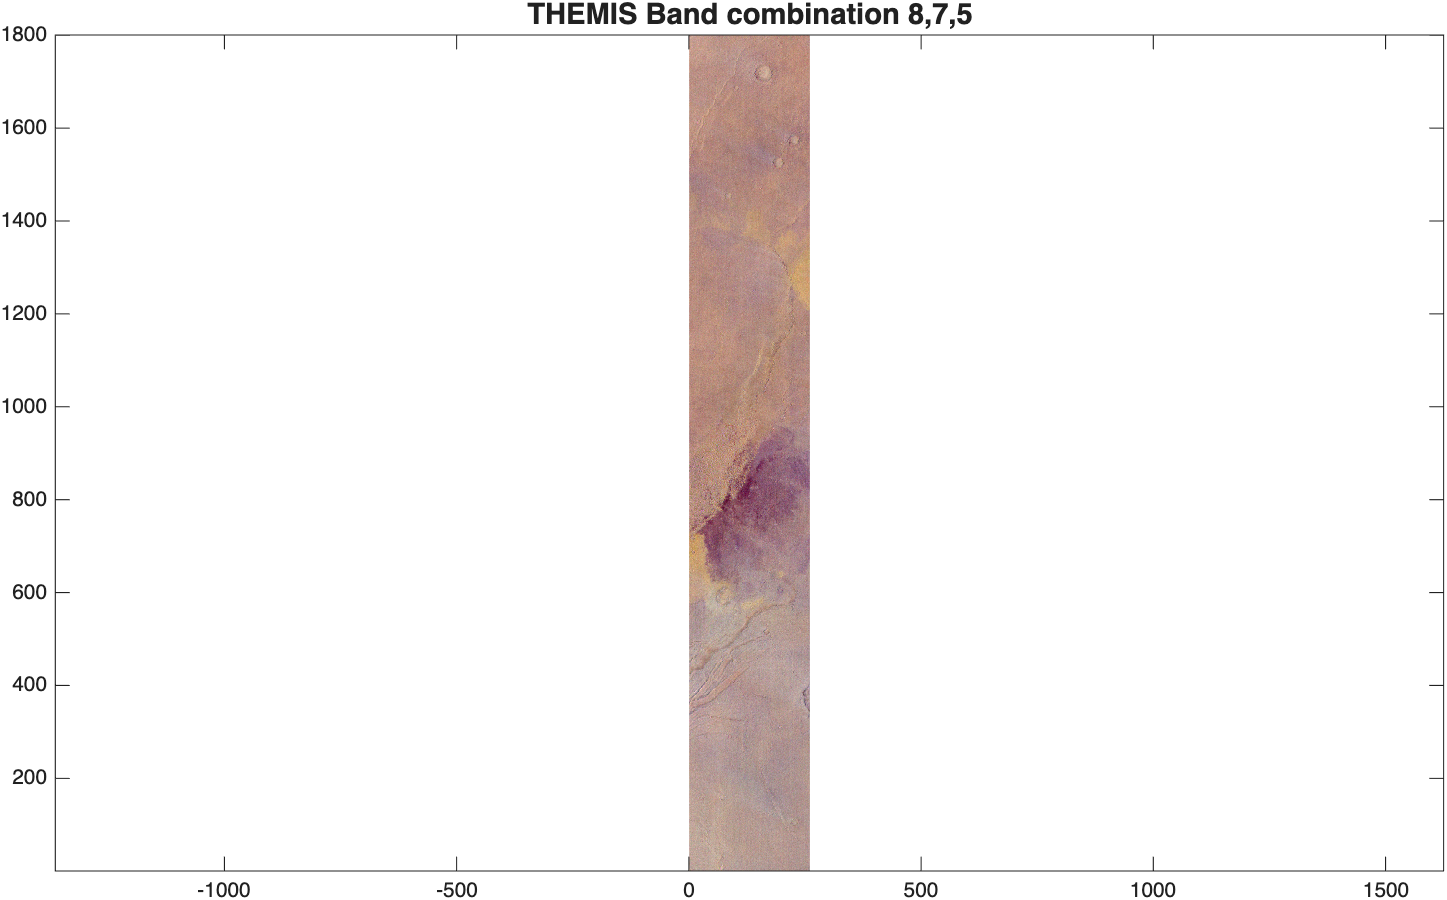 | 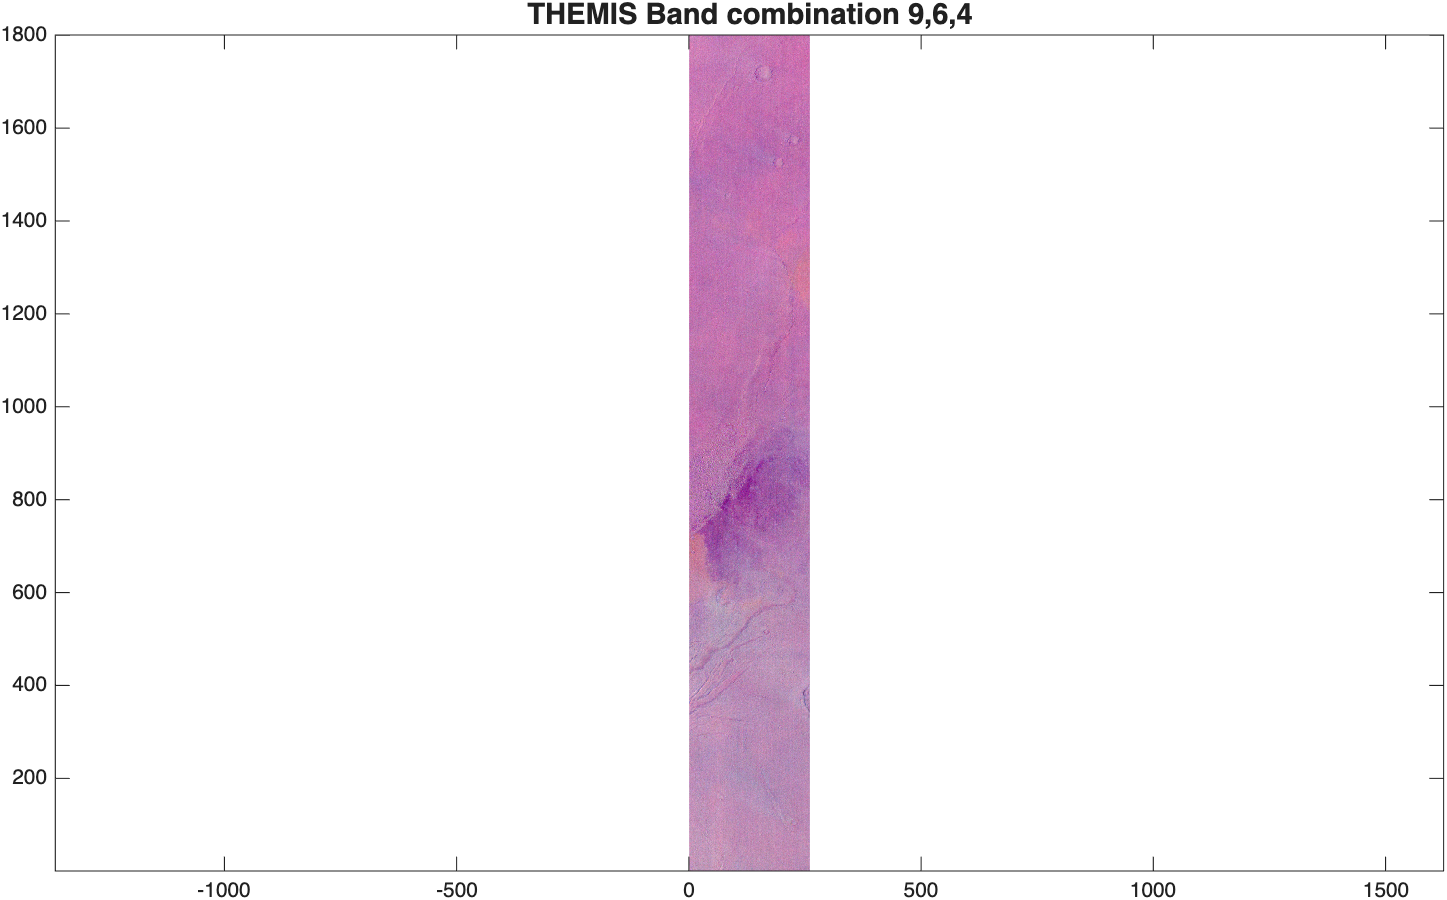 |

The band combinations `9,6,4` scene looks more pink than the scene shown in the combination `8,7,5`.

The pink colour for the most part is coming from the the smooth/flat surfaces distributed on the upper and lower part of the images.

A purple colour indicates stronger signal in the `Red` and `Blue` channels, in which in this case, corresponding to band 9 and 4 in the `Combination 9,6,4` image.

Differences in these scenes, establish that, the surface in the AOI exhibits stronger emissivity in 8.56 and 12.57 microns wavelength; in the NIR and SWIR than the 10.21 microns

Comparing to the scene with `Combination 8,7,5`, where the `Red` and `Blue` channels are reserved for band 8 and 5, and the image is dominated why warm colour like yellow, suggest stronger emissivity in `Red` and `Green`

The purple colour is sparsely distributed, so emissivity in this scene is dominated by 11.79 and 11.04 microns.

smooth area of the surface

bottom of 875 looks more greenish


# Mineralogical Composition – TES


In [ ]:
engine.eval(
    # Load TES data file
    "specinit;" \
    "plotwb2(squeeze(unit1.xaxis),squeeze(unit1.data(1,:,:)))" \
    ""
    ""
)

```bash
    {'Quartz BUR-4120 136'                 }
    {'Microcline BUR-3460 95'              }
    {'Albite WAR-0244 4'                   }
    {'Oligoclase BUR-060D 15'              }
    {'Andesine BUR-240 79'                 }
    {'Labradorite WAR-4524 10'             }
    {'Bytownite WAR-1384 76'               }
    {'Anorthite BUR-340 123'               }
    {'Actinolite HS-116.4B 26'             }
    {'Biotite BUR-840 80 50% BB'           }
    {'Muscovite WAR-5474 17'               }
    {'Chlorite WAR-1924 9'                 }
    {'Enstatite HS-9.4B 51'                }
    {'Bronzite NMNH-93527 58'              }
    {'Diopside WAR-6474 69'                }
    {'Augite NMNH-9780 57'                 }
    {'Augite NMNH-122302 134'              }
    {'Hedenbergite, manganoan DSM-HED01 59'}
    {'Serpentine HS-8.4B 24'               }
    {'Serpentine BUR-1690 34'              }
    {'Forsterite AZ-01 5'                  }
    {'Fayalite WAR-RGFAY01 167'            }
    {'Hematite BUR-2600 30'                }
    {'Anhydrite ML-S9 103 40% BB'          }
    {'Gypsum ML-S6 100'                    }
    {'Calcite C27 114'                     }
    {'Dolomite C28 142'                    }
    {'Nontronite WAR-5108g granular 151'   }
    {'Fe-smectite SWa-1s solid 157'        }
    {'Illite IMt-2g granular 93'           }
    {'SiK Glass MW-SiK-GLASS 32'           }
    {'Surface Dust'                        }
```


### Q6: What is the lowest rms error you can find? (If you can somehow beat the least squares value of .0019, you get an A!!)

The lowest rms error you found is `0.0074`,

![q6_ c.png](<figs/q6_ c.png>)

### Q7: What are the best fit values you find for each mineral group?

The values of each mineral group I found for the best fit lne is as follow,

```matlab
Quartz = ~3%
Feldspar = 16%
Amphibole = 0%
High-silica = 3.%
Orthopyroxene = 2%
Clinopyroxene = 27%
Serpentine = 0%
Olivine = 0%
Hematite = 3%
Sulfate = 5%
Carbonate = 10%
Surface-Dust = 6%
Atmosphere = 87%
```


### Q8: Try to guess what transitions might be (generally) responsible for these features.

- For those in the 10-11 microns range, the features could be primarily explained through stretching vibrational Si-O, which are found in fledspar, pyroxene, and olivine.
- For those occurring at longer wavelength than 10-11 microns are mostly lower energy bending/lattice vibrational modes.

compositional...

carbonate minerals most responsible at 3 microns


### Q9: Which are the most important minerals to the best fit spectrum? How does this compare with the fit you found by hand?


In [ ]:
engine.eval(
    "specview2(u1,lib,atm);",
    nargouts = 2
)

![Figure_8.png](figs/Figure_8.png)


The most important minerals are `Feldspar` and `Clinopyroxene`. `Feldspar` reduces the error from the baseline of $0.0635$ to $0.0472$. `Clinopyroxene` reduces the error from the baseline to $0.0424$. This matches up with the abundance (%) I fitted in the pervious question, `Feldspar` and `Clinopyroxene` each takes up `16%` adn `23%` of the atmosphere respectively.

<!--
23% of clinopyroxene reduces the `rms error` from the baseline of $0.0635$ to $0.0424$

16% of feldspar reduces `rms error` from the base line to $0.0531$ -->


### Q10: What are the fewest number of components which provide a reasonably good fit to the spectrum?

The fewest number of minerals among the ones which are none-zero, are `quartz`, `high-silica`, `orthopyroxene`, and `hematite`.
Quartz reduces the baseline to only $0.0624$.

High-silica reduces rms to $0.0586$

Orthopyroxene reduces rms to $0.0620$

hematite reduces the rms to $0.0619$

This also supports my fitted model from the previous question, with each of them taking up roughly $~2-3\%$ of atmosphere.


### Q11: What are the major differences in mineral abundances?


In [ ]:
engine.eval(
    "[u1.groupcoeff(:,1) u2.groupcoeff(:,1)]",
    nargout=0
)

Fitted resolution

| Mineral / Component                         | u1 (Coefficient ± SD) | u2 (Coefficient ± SD) |
| :------------------------------------------ | --------------------: | --------------------: |
| Quartz                                      |       0.0062 ± 0.0096 |       0.0033 ± 0.0084 |
| Feldspar                                    |       0.2550 ± 0.0807 |       0.2280 ± 0.0708 |
| Amphibole                                   |       0.0267 ± 0.0259 |       0.0017 ± 0.0227 |
| High-silica phase (glass or sheet-silicate) |       0.0321 ± 0.1169 |       0.2090 ± 0.1025 |
| Orthopyroxene                               |       0.0163 ± 0.0615 |       0.0333 ± 0.0539 |
| Clinopyroxene                               |       0.2365 ± 0.0568 |       0.1155 ± 0.0498 |
| Serpentine                                  |       0.0191 ± 0.0605 |       0.0000 ± 0.0530 |
| Olivine                                     |       0.0000 ± 0.0413 |       0.0000 ± 0.0362 |
| Hematite                                    |       0.0231 ± 0.0431 |       0.0281 ± 0.0378 |
| Sulfate                                     |       0.0564 ± 0.0337 |       0.0574 ± 0.0295 |
| Carbonate                                   |       0.0843 ± 0.0175 |       0.0723 ± 0.0153 |
| Surface Dust                                |       0.0001 ± 0.2257 |       0.0010 ± 0.1978 |
| Atmosphere                                  |       0.9934 ± 0.1838 |       1.0782 ± 0.1611 |
| Black Body                                  |      -0.7461 ± 0.3464 |      -0.8271 ± 0.3037 |

The major differences lies in `amphibole`, `high-silica` and `orthopyroxene`


### Q12: are there any mineral detections that are not statistically significant (at the 1-sigma level)?

A detection is not statistically significant at $1\sigma$ level if:
$$Z = \frac{\text{coeff}}{\sigma} > 1$$

|               | Unit1             | Unit2            |
| ------------- | ----------------- | ---------------- |
| Quartz        | 0.0062/0.0096 ❌  | 0.0033/0.0084 ❌ |
| Feldspar      | 0.255/0.0807 ✅   | 0.2280/0.0708 ✅ |
| Ampshbole     | .0267 / .0259 ✅  | 0.0017/0.0227 ❌ |
| High-silica   | .0321/0.1169 ❌   | 0.2090/0.1025 ✅ |
| Orthopyroxene | .0163 / 0.0615 ❌ | 0.0333/0.0539 ❌ |
| Clinopyroxene | .2365/0.0568 ✅   | 0.1155/0.0498 ✅ |
| Serpentine    | .0191/.0605 ❌    | 0/0.0530 ❌      |
| Olivine       | 0 / 0.0413 ❌     | 0/0.0362 ❌      |
| Hematite      | 0.0231/0.0431 ❌  | 0.0281/0.0378 ❌ |
| Sulfate       | 0.0564/0.0337 ✅  | 0.0574/0.0295 ❌ |
| Carbonate     | 0.0843/0.0175 ✅  | 0.0723/0.0153 ✅ |
| Surface dust  | 0.0001/0.2257 ❌  | 1.0782/0.1611 ✅ |

For unit 1, `feldspar`, `ampshbole`, `clinopyroxene`, `sulfate`, and `carbonate` are statistically significant whereas the rest are statistically insignificant.

For unit 2, `feldspar`, `high-silica`, `clinopyroxene`, `carbonate`, and `surface dust` are statistically significant.

For those that are deemed statistically insignificant, their `abundance coefficient` are larger than their `standardized error`, meaning, the room of error is greater than the suggested abundance coefficient, rendering the detection statistically insignificant.

<!-- signal to noise ratio -->

<!-- Now, looking at the standard error magnitudes, -->


### Q13: Is the difference in say, `carbonate` between the two units significant? What about the difference in `high-silica` phases?

- The `carbonate` differences between unit 1 and 2

$$
\begin{gather}
Z = \frac{|0.0843 - 0.0723|}{\sqrt{.0175^2 + .0153^2}} = 0.518
\end{gather}
$$

0.0843, 0.0723

0.0175, 0.0153

0.0876

- The high-silica differences between unit 1 and 2,
  abundance coefficient, 0.0321, 0.2090

errors 0.1169 0.1025

significant

$$
\begin{gather}
Z = \frac{|0.0321 - 0.2090|}{\sqrt{0.1169^2 + 0.1025^2}} = 1.38
\end{gather}
$$


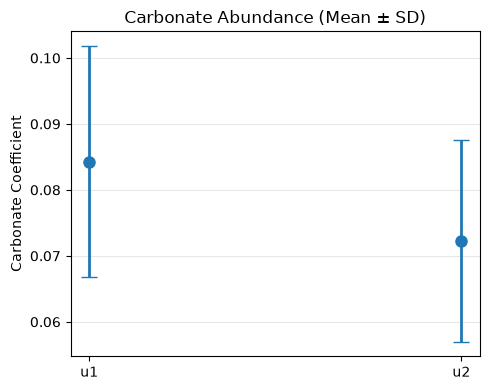

In [5]:
import matplotlib.pyplot as plt

means = [0.0843, 0.0723]
stds = [0.0175, 0.0153]
labels = ["u1", "u2"]

fig, ax = plt.subplots(figsize=(5, 4))

ax.errorbar(
    labels,
    means,
    yerr=stds,
    fmt="o",
    capsize=6,
    markersize=8,
    linewidth=2
)

ax.set_ylabel("Carbonate Coefficient")
ax.set_title("Carbonate Abundance (Mean ± SD)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

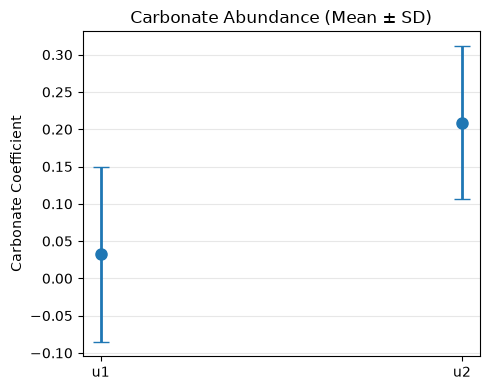

In [6]:
import matplotlib.pyplot as plt

means = [0.0321, 0.2090]
stds = [0.1169, 0.1025]
labels = ["u1", "u2"]

fig, ax = plt.subplots(figsize=(5, 4))

ax.errorbar(
    labels,
    means,
    yerr=stds,
    fmt="o",
    capsize=6,
    markersize=8,
    linewidth=2
)

ax.set_ylabel("Carbonate Coefficient")
ax.set_title("Carbonate Abundance (Mean ± SD)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Q14: Using the compositional, morphologic, and stratigraphic relationships present in the various datasets you have analyzed, what can you say about the geologic history of this area?

volcanic activities, basalt, relatively dust free due to wind, the IR analysis is relative easy to perform.

10 -11 microns absorption features of Si-O,

this dark patch is made of high-silica.

high pressure will cause transitions.
